# Módulo 07: Sedimentación en Canales, Fosas y Puertos (`sedmor.sedimentation`)

El dragado de mantenimiento suele constituir el mayor coste operativo de puertos y vías navegables. Este módulo implementa las herramientas del paquete 2013 para dimensionar tasas de aterramiento por fracciones granulométricas (arena, limo y arcilla) e intercambio mareal/densitario.

### Objetivos de aprendizaje
1. Calcular la **sedimentación anual en un canal o fosa transversal** (`channel_sedimentation`), comparando el método de van Rijn con Eysink-Vermaas.
2. Evaluar el **azolvamiento portuario de arena** (`harbour_sand_sedimentation`) y de **fango por intercambio mareal** (`harbour_mud_sedimentation`).
3. Modelar la **evolución morfológica 1D** a lo largo de un tubo de corriente bajo corriente unidireccional (`streamtube_sedimentation`) y marea simétrica (`streamtube_tidal_sedimentation`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} cargada.")


Librería sedmor v0.1.0 cargada.


## 1. Sedimentación en Canal de Navegación (Comparación de Métodos y Fracciones)

Analizamos un canal de $L = 800\,\text{m}$ de longitud y $B = 250\,\text{m}$ de ancho dragado desde $h_{\text{out}} = 9\,\text{m}$ hasta $h_{\text{in}} = 16\,\text{m}$ en una zona estuarina con 12 clases hidráulicas anuales.


van Rijn        -> Depósito anual: 1,361,427 m³ | Espesor: 6.81 m | Eficiencia trap: 13.0%
Eysink-Vermaas  -> Depósito anual: 1,402,689 m³ | Espesor: 7.00 m | Eficiencia trap: 13.4%


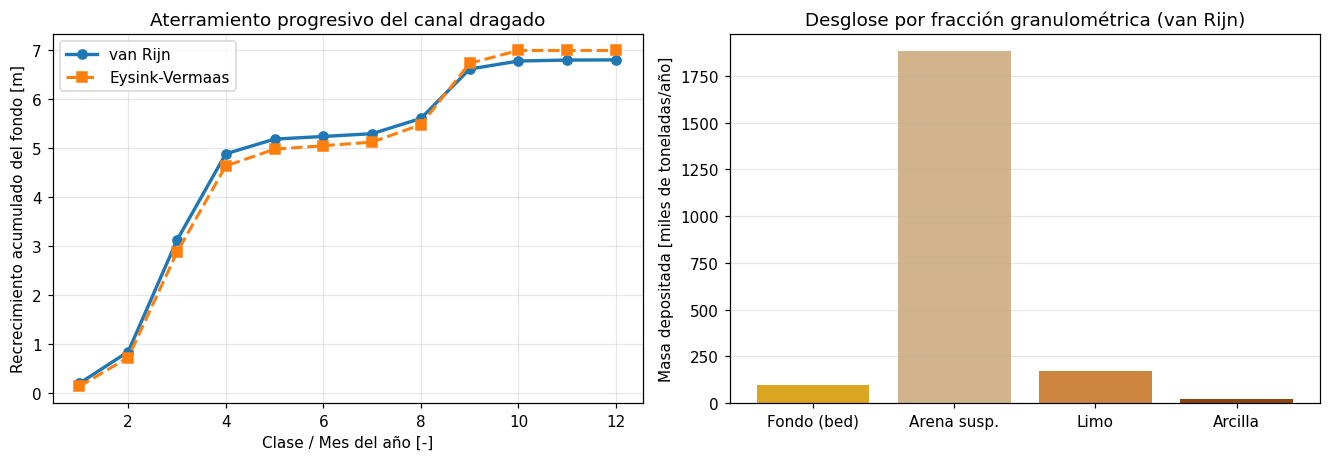

In [2]:
common_pit = dict(
    length=800.0, width=250.0, depth_in=16.0, depth_out=9.0,
    dur_h=[730.0] * 12,
    alpha0_deg=[65.0] * 12,
    b0=[1.0] * 12,
    dh_wl=[0.2, 0.5, 0.8, 0.8, 0.5, 0.2, -0.2, -0.5, -0.8, -0.8, -0.5, -0.2],
    u0=[0.35, 0.55, 0.75, 0.75, 0.55, 0.35, 0.35, 0.55, 0.75, 0.75, 0.55, 0.35],
    hs=[0.8, 1.0, 1.4, 1.4, 1.0, 0.8, 0.8, 1.0, 1.4, 1.4, 1.0, 0.8],
    tp=[7.0] * 12,
    c_clay=[0.06] * 12,
    c_silt=[0.04] * 12,
    d50=0.0002, d90=0.0003, cal_tr=0.8,
)

pit_vr = sm.sedimentation.channel_sedimentation(**common_pit, trap_method=1)
pit_ev = sm.sedimentation.channel_sedimentation(**common_pit, trap_method=2)

print(f"van Rijn        -> Depósito anual: {pit_vr.total_deposition_m3:,.0f} m³ | Espesor: {pit_vr.total_layer_thickness_m:.2f} m | Eficiencia trap: {pit_vr.trap_efficiency_volume*100:.1f}%")
print(f"Eysink-Vermaas  -> Depósito anual: {pit_ev.total_deposition_m3:,.0f} m³ | Espesor: {pit_ev.total_layer_thickness_m:.2f} m | Eficiencia trap: {pit_ev.trap_efficiency_volume*100:.1f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.3))

meses = np.arange(1, 13)
ax1.plot(meses, pit_vr.cum_dh_m, "o-", lw=2.2, label="van Rijn")
ax1.plot(meses, pit_ev.cum_dh_m, "s--", lw=2.0, label="Eysink-Vermaas")
ax1.set_xlabel("Clase / Mes del año [-]")
ax1.set_ylabel("Recrecimiento acumulado del fondo [m]")
ax1.set_title("Aterramiento progresivo del canal dragado")
ax1.grid(alpha=0.3)
ax1.legend()

fracs = ["Fondo (bed)", "Arena susp.", "Limo", "Arcilla"]
vr_tons = [
    np.sum(pit_vr.deposition_bed_tons),
    np.sum(pit_vr.deposition_sand_tons),
    np.sum(pit_vr.deposition_silt_tons),
    np.sum(pit_vr.deposition_clay_tons),
]
ax2.bar(fracs, np.array(vr_tons) / 1e3, color=["goldenrod", "tan", "peru", "saddlebrown"])
ax2.set_ylabel("Masa depositada [miles de toneladas/año]")
ax2.set_title("Desglose por fracción granulométrica (van Rijn)")
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()


## 2. Azolvamiento en Dársena Portuaria y Evolución en Tubo de Corriente

Evaluamos la dinámica temporal de concentración en una dársena sujeta a intercambio mareal y corriente de densidad (`harbour_mud_sedimentation`), así como la migración/relleno 1D de una zanja submarina en un tubo de corriente (`streamtube_sedimentation`).


Dársena portuaria -> Volumen depositado/año: 1,726,700 m³/año | Tasa recrecimiento: 0.785 m/año


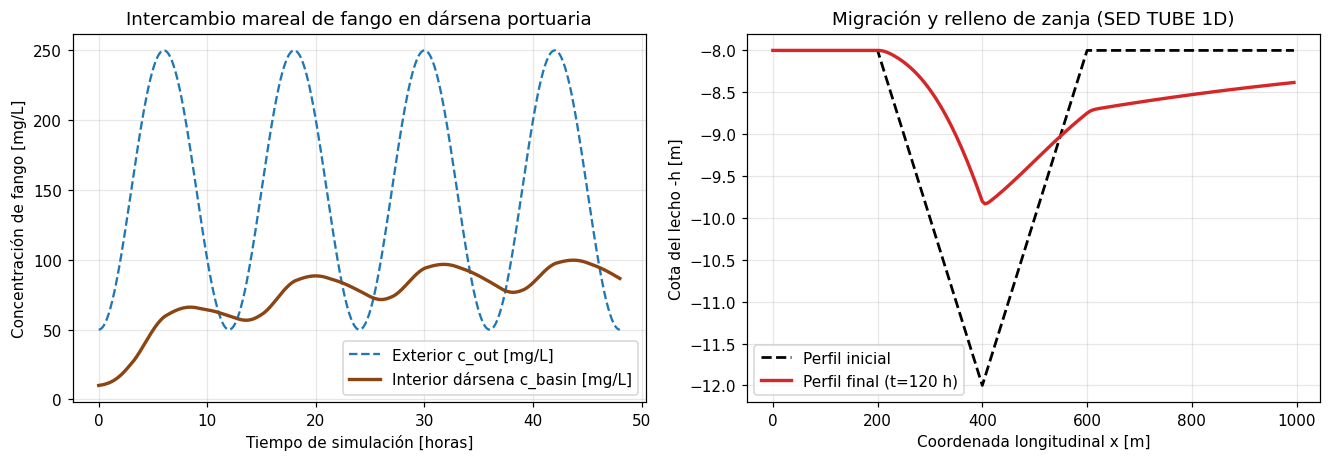

In [3]:
harb = sm.sedimentation.harbour_mud_sedimentation(
    depth_msl=10.7, entrance_width=220.0, basin_area=2_200_000.0,
    u_peak_out=0.8, tidal_amplitude=1.5, c_out_mean=0.15, c_out_amp=0.10, n_tides_sim=4
)
print(f"Dársena portuaria -> Volumen depositado/año: {harb.deposition_per_year_m3:,.0f} m³/año | Tasa recrecimiento: {harb.layer_thickness_per_year_m:.3f} m/año")

# Evolución 1D en zanja transversal sobre tubo de corriente (50 pasos)
x_st = np.arange(200, dtype=float) * 5.0
h_st_init = np.interp(x_st, [0.0, 200.0, 400.0, 600.0, 995.0], [8.0, 8.0, 12.0, 8.0, 8.0])
st_res = sm.sedimentation.streamtube_sedimentation(
    x=x_st, width=np.ones_like(x_st), h_init=h_st_init,
    hs=np.full_like(x_st, 0.8), tp=np.full_like(x_st, 6.0),
    discharge=12.0, bc_mode=1, bc_qsus=2.0, dt_hours=2.0, n_steps=60
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.3))

ax1.plot(harb.t_s / 3600.0, harb.c_out_kg_m3 * 1000, "--", label="Exterior c_out [mg/L]")
ax1.plot(harb.t_s / 3600.0, harb.c_basin_kg_m3 * 1000, lw=2.2, color="saddlebrown", label="Interior dársena c_basin [mg/L]")
ax1.set_xlabel("Tiempo de simulación [horas]")
ax1.set_ylabel("Concentración de fango [mg/L]")
ax1.set_title("Intercambio mareal de fango en dársena portuaria")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.plot(st_res.x_m, -st_res.h_initial_m, "k--", lw=1.8, label="Perfil inicial")
ax2.plot(st_res.x_m, -st_res.h_final_m, color="tab:red", lw=2.2, label="Perfil final (t=120 h)")
ax2.set_xlabel("Coordenada longitudinal x [m]")
ax2.set_ylabel("Cota del lecho -h [m]")
ax2.set_title("Migración y relleno de zanja (SED TUBE 1D)")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


### Ejercicios propuestos
1. En `harbour_mud_sedimentation`, reduzca `delta_rho_max` de `3.0 kg/m³` a `0.0 kg/m³` (eliminando las corrientes de densidad por salinidad/agua dulce) y observe cuánto disminuye el volumen depositado anual.
2. En `channel_sedimentation`, analice el efecto de reducir la profundidad dragada `depth_in` de `16 m` a `13 m` sobre la eficiencia de atrapamiento.
